# 5. What the group report checks

`glmfitlins report` makes `statsmodel_specs/<dataset>/group_<task>/` in six steps. This notebook runs a small
version of each step on live OpenNeuro data so you can see what it computes and how to read it:

1. Copy example contrast/design figures
2. **VIF** of every design matrix
3. **R-squared** mean/std maps across runs
4. **R-squared similarity** with the MNI brain mask (finds poorly normalised runs)
5. **Group z-maps** per contrast
6. Write the group README

To keep downloads small the notebook uses at most `MAX_IMAGES` runs (about 1.6 MB each); raise it for a fuller picture.

In [1]:
import json, re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 140)

# Make `nb_utils` importable whether Jupyter was started in notebooks/ or at the repo root
NB_DIR = Path.cwd() if (Path.cwd() / "nb_utils.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB_DIR))
import nb_utils as nbu

REPO = NB_DIR.parent
SPECS = REPO / "statsmodel_specs"

import nibabel as nib
import seaborn as sns
from nilearn import plotting
from nilearn.image import new_img_like
from nilearn.interfaces.bids import parse_bids_filename
from openneuro_glmfitlins.qc.similarity import calc_niftis_meanstd, get_low_quality_subs, similarity_boldstand_metrics
from openneuro_glmfitlins.qc.vif import gen_vifdf
from openneuro_glmfitlins.reports.groupmap import NOISE_REG, build_contrast_dict, ReportOptions
from openneuro_glmfitlins.specs.summary import extract_model_info

In [ ]:
DATASET = "ds003425"
TASK = "learning"
MAX_IMAGES = 12        # runs to download for the R2 / VIF checks

opts = ReportOptions()  # the report's defaults
DICE_THRESH, VOXOUT_THRESH, Z_THRESH = opts.dice_thresh, opts.voxout_thresh, opts.zstat_thresh
print(f"report defaults: dice < {DICE_THRESH} and voxels outside mask > {VOXOUT_THRESH}% flag a run; z threshold {Z_THRESH}")

report defaults: dice < 0.85 and voxels outside mask > 0.1% flag a run; z threshold 2.3


## Setup: pick runs from OpenNeuro

The report uses *every* run; here we take an evenly spread subset of the run-level R-squared maps and design matrices.

In [3]:
inv = pd.DataFrame(nbu.list_deriv_files(DATASET, TASK))
inv["tag"] = inv["key"].map(lambda k: parse_bids_filename(k)["file_tag"])
inv["stat"] = inv["key"].map(lambda k: parse_bids_filename(k).get("stat"))
r2_all = inv[inv["stat"] == "rSquare"].sort_values("key")
des_all = inv[inv["key"].str.endswith("_design.tsv")].sort_values("key")

def spread(df, n):
    return list(df["key"].iloc[np.linspace(0, len(df) - 1, min(n, len(df))).round().astype(int)])

r2_keys, des_keys = spread(r2_all, MAX_IMAGES), spread(des_all, MAX_IMAGES)
print(f"{len(r2_all)} R-squared maps and {len(des_all)} design matrices available; using {len(r2_keys)} / {len(des_keys)}")

spec_file = SPECS / DATASET / f"{DATASET}-{TASK}_specs.json"
spec_results = extract_model_info(model_spec=json.loads(spec_file.read_text()))
basic = json.loads((SPECS / DATASET / f"{DATASET}_basic-details.json").read_text())
plot_coords = tuple(basic["Tasks"][TASK].get("plot_coords") or (0, 0, 0))

72 R-squared maps and 72 design matrices available; using 12 / 12


## Step 1: the published report

If this repository already has a report for the study, here is what it contains (steps 2 to 5 below recreate
the main pieces).

In [4]:
group_dir = SPECS / DATASET / f"group_{TASK}"
if group_dir.exists():
    print(*sorted(p.name for p in (group_dir / "files").glob("*"))[:20], sep="\n")
    readme = (group_dir / "README.md").read_text().splitlines()
    print("\n--- README.md (first lines) ---"); print("\n".join(readme[:12]))
else:
    print(f"No report at {group_dir} yet. Create it with:  uv run glmfitlins report -d {DATASET} -t {TASK}")

ds003425_task-learning_contrast-matrix.svg
ds003425_task-learning_design-matrix.svg
ds003425_task-learning_design-matrix.tsv
ds003425_task-learning_hist-dicesimilarity.png
ds003425_task-learning_hist-dicesimilarity.tsv
ds003425_task-learning_hist-voxoutmask.png
ds003425_task-learning_rsquare-mean.png
ds003425_task-learning_rsquare-std.png
ds003425_task-learning_ses-01_contrast-ICSPvICSN_map.png
ds003425_task-learning_ses-01_contrast-VCSPshck_map.png
ds003425_task-learning_ses-01_contrast-VCSPvVCSN_map.png
ds003425_task-learning_vif-boxplot.png

--- README.md (first lines) ---
# ds003425: learning Task Analysis Report

The size of the Fitlins Derivatives for ds003425 learning is 8.8M with 1964 files.

Dataset- and task-relevant citations may be found in the papers: [Paper 1](https://www.nature.com/articles/s41598-022-05019-y).

## 1. Statistical Analysis [Boilerplate]

The below is an automatically generated report for the statistical analyses performed on this task and dataset. Some re

## Step 2: VIF of the design matrices

The report computes VIF for each contrast and task regressor in every design matrix, then plots the distribution.
Narrow boxes close to 1 mean the design estimates the contrasts efficiently in all runs.

Contrasts: {'VCSPvVCSN': '1*`trial_type.2` - 1*`trial_type.4`', 'ICSPvICSN': '1*`trial_type.3` - 1*`trial_type.5`', 'VCSPshck': '1*`trial_type.1`'}


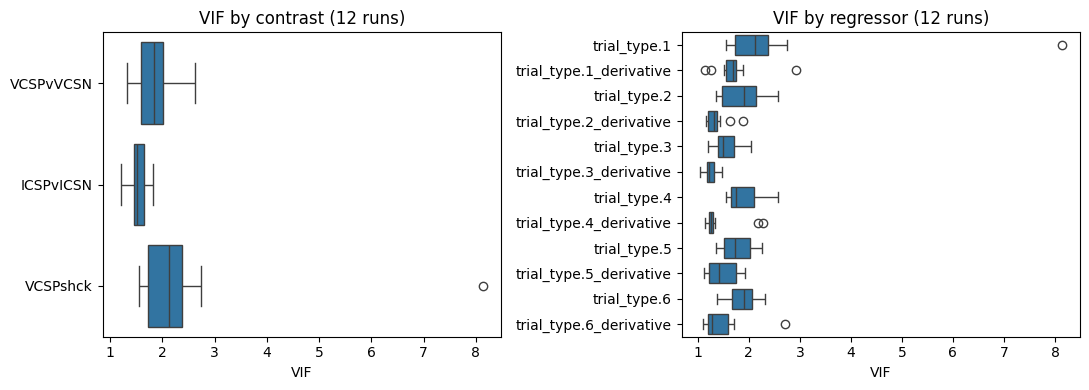

In [5]:
contrast_dict = build_contrast_dict(spec_results)
print("Contrasts:", contrast_dict)

vifs = []
for key in des_keys:
    d = pd.read_csv(nbu.fetch(nbu.DERIV_BUCKET, key), sep="\t")
    noise = [c for c in d.columns if any(n in c for n in NOISE_REG)]
    _, _, vdf = gen_vifdf(designmat=d, contrastdict=contrast_dict, nuisance_regressors=noise)
    vdf["design"] = key.split("/")[-1]
    vifs.append(vdf)
vif_all = pd.concat(vifs, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ["contrast", "regressor"]):
    sns.boxplot(data=vif_all[vif_all["type"] == kind], y="name", x="value", ax=ax)
    ax.set_title(f"VIF by {kind} ({len(des_keys)} runs)"); ax.set_ylabel(""); ax.set_xlabel("VIF")
plt.tight_layout(); plt.show()

## Step 3: R-squared mean and standard deviation

R-squared is the fraction of each voxel's variance the model explains in one run. Averaging across runs shows where
the model explains signal (typically grey matter and task-active regions); the standard deviation shows where runs disagree.

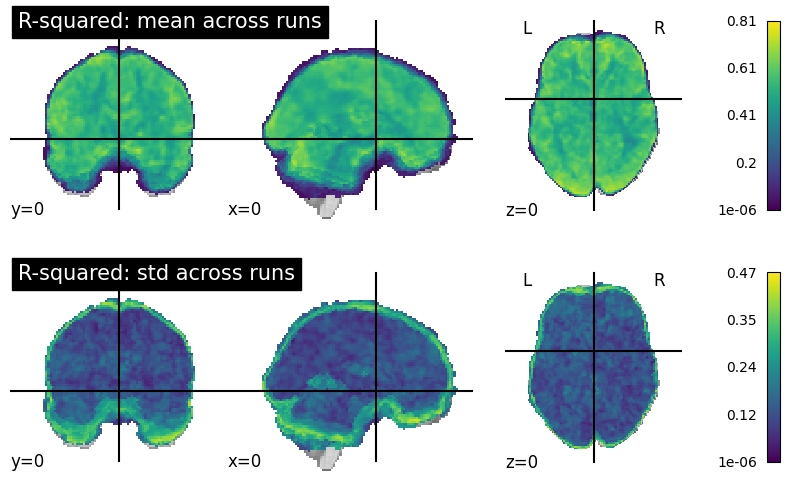

In [6]:
sq_dir = nbu.CACHE_DIR / "squeezed"; sq_dir.mkdir(parents=True, exist_ok=True)

def squeeze3d(key):
    """R2 maps are x*y*z*1; the report squeezes them to 3D before any comparison."""
    out = sq_dir / key.split("/")[-1]
    if not out.exists():
        img = nib.load(nbu.fetch(nbu.DERIV_BUCKET, key))
        new_img_like(img, img.get_fdata().squeeze()).to_filename(out)
    return out

r2_paths = [squeeze3d(k) for k in r2_keys]
mean_img, std_img = calc_niftis_meanstd([str(p) for p in r2_paths])

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_stat_map(mean_img, cut_coords=plot_coords, axes=axes[0], title="R-squared: mean across runs", cmap="viridis", colorbar=True)
plotting.plot_stat_map(std_img, cut_coords=plot_coords, axes=axes[1], title="R-squared: std across runs", cmap="viridis", colorbar=True)
plt.show()

## Step 4: R-squared similarity with the MNI brain mask

A run that normalised well has R-squared values inside the brain and almost none outside. For each run the report computes:
- **Dice** between the R-squared map's non-zero voxels and the MNI brain mask (1 = identical),
- **voxels outside the mask** (percent of non-zero voxels outside the brain).

A run is flagged when `dice < DICE_THRESH` **and** `voxoutmask > VOXOUT_THRESH`. Change the thresholds above to see who is flagged.

In [7]:
try:
    from templateflow import api
    mask_path = str(api.get(opts.template, desc="brain", resolution=opts.template_resolution, suffix="mask", extension="nii.gz"))
except Exception as err:  # offline / templateflow not configured
    print("templateflow unavailable, using the bundled mask:", err)
    mask_path = str(REPO / "examples/nilearn_pilots/mask/MNI152NLin2009cAsym_res-02_desc-brain_mask.nii.gz")
print("Brain mask:", mask_path)

ratio_df = pd.DataFrame([similarity_boldstand_metrics(str(p), mask_path) for p in r2_paths])
ratio_df.round(3)

Brain mask: /Users/demidenm/.cache/templateflow/tpl-MNI152NLin2009cAsym/tpl-MNI152NLin2009cAsym_res-02_desc-brain_mask.nii.gz


,img1,img2,dice,voxinmask,voxoutmask,ratio_inoutmask
0,sub-02_ses-01_run-01,mni152,0.891,96.267,3.733,25.791
1,sub-03_ses-01_run-01,mni152,0.923,97.055,2.945,32.952
2,sub-04_ses-01_run-02,mni152,0.905,99.059,0.941,105.273
3,sub-05_ses-01_run-02,mni152,0.914,94.888,5.112,18.562
4,sub-06_ses-01_run-03,mni152,0.915,96.337,3.663,26.301
5,sub-07_ses-01_run-03,mni152,0.944,97.640,2.360,41.372
6,sub-08_ses-01_run-04,mni152,0.913,95.851,4.149,23.103
7,sub-09_ses-01_run-04,mni152,0.915,96.792,3.208,30.174
8,sub-10_ses-01_run-05,mni152,0.913,94.466,5.534,17.069
9,sub-11_ses-01_run-05,mni152,0.898,98.453,1.547,63.623


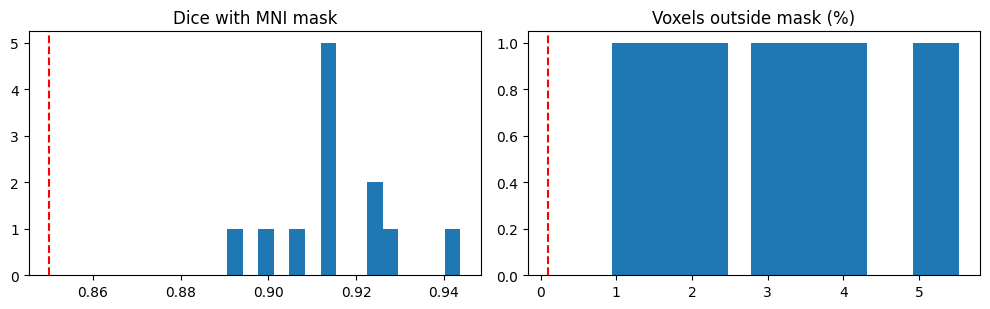

Flagged runs: none


In [13]:
bin_size=15
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(ratio_df["dice"], bins=bin_size); axes[0].axvline(DICE_THRESH, color="r", ls="--"); axes[0].set_title("Dice with MNI mask")
axes[1].hist(ratio_df["voxoutmask"], bins=bin_size); axes[1].axvline(VOXOUT_THRESH, color="r", ls="--"); axes[1].set_title("Voxels outside mask (%)")
plt.tight_layout(); plt.show()

low = get_low_quality_subs(ratio_df, dice_thresh=DICE_THRESH, voxout_thresh=VOXOUT_THRESH)
print("Flagged runs:", low or "none")

Flagged runs are candidates for exclusion: look at their maps before dropping them. If you drop a run or
subject, edit the subjects file and re-run `spec --update`, `fit` and `report`.

## Step 5: group z-maps

The last figure set is the group z-map per contrast, thresholded at `Z_THRESH` and centred on the study's `plot_coords`.

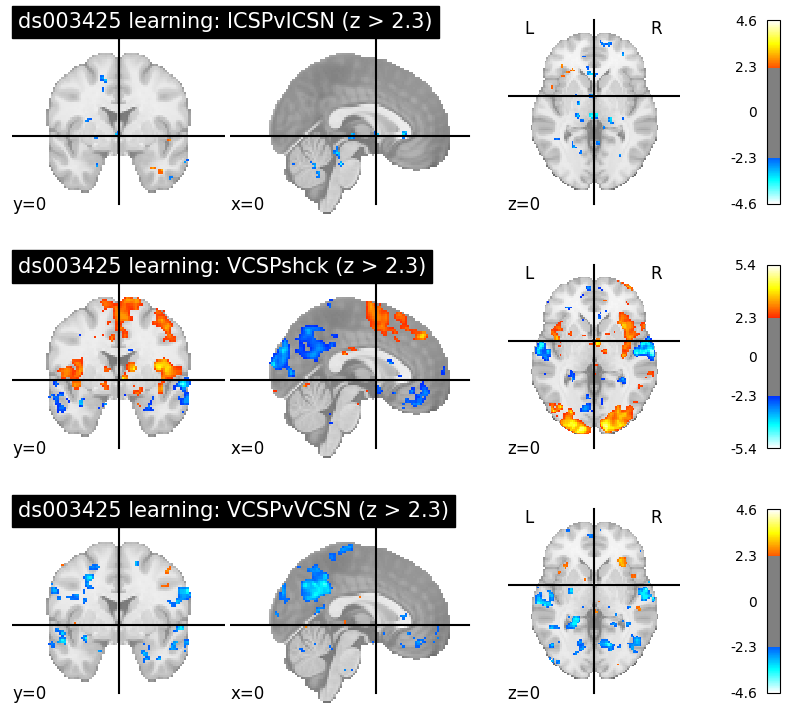

In [14]:
grp = inv[(inv["key"].str.contains("node-dataLevel/")) & (inv["stat"] == "z") & (inv["tag"] == "statmap")].sort_values("key")
fig, axes = plt.subplots(len(grp), 1, figsize=(10, 3 * len(grp)))
for ax, key in zip(np.atleast_1d(axes), grp["key"]):
    name = parse_bids_filename(key)["contrast"]
    plotting.plot_stat_map(str(nbu.fetch(nbu.DERIV_BUCKET, key)), threshold=Z_THRESH, cut_coords=plot_coords, axes=ax,
                           title=f"{DATASET} {TASK}: {name} (z > {Z_THRESH})", colorbar=True)
plt.show()

## Step 6: the README

The report ends by writing `group_<task>/README.md`: study details, citation links, model description (HRF,
smoothing, contrasts), the figures above and the list of flagged runs.

## Run it for real

```bash
uv run glmfitlins report -d <dataset> -t <task>     # needs your FitLins output (see notebooks 1 and 4)
```

Each step prints a progress header (`[1/6]` ... `[6/6]`).